In [1]:
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Устройство для вычислений:', DEVICE)
print('Версия PyTorch:', torch.__version__)

Устройство для вычислений: cpu
Версия PyTorch: 2.14.1+cpu


In [2]:
COLUMNS = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num',
    'marital-status', 'occupation', 'relationship', 'race', 'sex',
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
]
DATA_URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data'

df = pd.read_csv(DATA_URL, header=None, names=COLUMNS,
                 skipinitialspace=True, na_values=['?'])
df['income'] = df['income'].astype(str).str.strip().str.rstrip('.')
df = df[df['income'].isin(['<=50K', '>50K'])].copy()
print('Размер набора данных:', df.shape)
print('Количество пропусков:', int(df.isna().sum().sum()))
print('Распределение целевой переменной:')
print(df['income'].value_counts().to_string())
display(df.head())

Размер набора данных: (32561, 15)
Количество пропусков: 4262
Распределение целевой переменной:
income
<=50K    24720
>50K      7841


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
X = df.drop(columns='income')
y = (df['income'] == '>50K').astype(np.float32)

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ('fill', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])
categorical_pipeline = Pipeline([
    ('fill', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor = ColumnTransformer([
    ('numbers', numeric_pipeline, numeric_cols),
    ('categories', categorical_pipeline, categorical_cols)
])

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
X_train = preprocessor.fit_transform(X_train_raw).astype(np.float32)
X_test = preprocessor.transform(X_test_raw).astype(np.float32)
y_train = y_train_raw.to_numpy(dtype=np.float32).reshape(-1, 1)
y_test = y_test_raw.to_numpy(dtype=np.float32).reshape(-1, 1)

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

print('Обучающая выборка:', X_train_tensor.shape)
print('Тестовая выборка:', X_test_tensor.shape)
print('Число входных признаков после кодирования:', X_train.shape[1])
print('Доля доходов >50K в обучении:', round(float(y_train.mean()), 4))

Обучающая выборка: torch.Size([26048, 105])
Тестовая выборка: torch.Size([6513, 105])
Число входных признаков после кодирования: 105
Доля доходов >50K в обучении: 0.2408


## 4. Определение архитектур MLP

In [4]:
class MLP(nn.Module):
    def __init__(self, input_size, hidden_sizes):
        super().__init__()
        layers = []
        previous_size = input_size
        for neurons in hidden_sizes:
            layers.append(nn.Linear(previous_size, neurons))
            layers.append(nn.ReLU())
            previous_size = neurons
        layers.append(nn.Linear(previous_size, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

input_size = X_train.shape[1]
model_basic = MLP(input_size, [32]).to(DEVICE)
model_deep = MLP(input_size, [16, 16]).to(DEVICE)
print('Базовая архитектура:', model_basic)
print('Углублённая архитектура:', model_deep)

Базовая архитектура: MLP(
  (network): Sequential(
    (0): Linear(in_features=105, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)
Углублённая архитектура: MLP(
  (network): Sequential(
    (0): Linear(in_features=105, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


## 5. Функция потерь, оптимизатор и цикл обучения




In [5]:
EPOCHS = 20
BATCH_SIZE = 256
LEARNING_RATE = 0.001

def train_model(model):
    loader = DataLoader(
        TensorDataset(X_train_tensor, y_train_tensor),
        batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(SEED)
    )
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {'train_loss': [], 'test_loss': []}
    start_time = time.perf_counter()

    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            loss = criterion(logits, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * xb.size(0)

        history['train_loss'].append(total_loss / len(loader.dataset))
        model.eval()
        with torch.no_grad():
            test_logits = model(X_test_tensor.to(DEVICE))
            test_loss = criterion(test_logits, y_test_tensor.to(DEVICE)).item()
        history['test_loss'].append(test_loss)

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f'Эпоха {epoch+1:2}/{EPOCHS}: '
                  f'ошибка обучения = {history["train_loss"][-1]:.4f}, '
                  f'ошибка теста = {test_loss:.4f}')

    elapsed = time.perf_counter() - start_time
    return history, elapsed

print('=== Обучение базовой сети (32) ===')
history_basic, time_basic = train_model(model_basic)
print(f'Время обучения: {time_basic:.2f} с')
print('=== Обучение углублённой сети (16 → 16) ===')
history_deep, time_deep = train_model(model_deep)
print(f'Время обучения: {time_deep:.2f} с')

=== Обучение базовой сети (32) ===
Эпоха  1/20: ошибка обучения = 0.5234, ошибка теста = 0.3729
Эпоха  5/20: ошибка обучения = 0.3162, ошибка теста = 0.3101
Эпоха 10/20: ошибка обучения = 0.3084, ошибка теста = 0.3049
Эпоха 15/20: ошибка обучения = 0.3051, ошибка теста = 0.3031
Эпоха 20/20: ошибка обучения = 0.3028, ошибка теста = 0.3023
Время обучения: 8.33 с
=== Обучение углублённой сети (16 → 16) ===
Эпоха  1/20: ошибка обучения = 0.5809, ошибка теста = 0.3819
Эпоха  5/20: ошибка обучения = 0.3150, ошибка теста = 0.3085
Эпоха 10/20: ошибка обучения = 0.3071, ошибка теста = 0.3027
Эпоха 15/20: ошибка обучения = 0.3042, ошибка теста = 0.3019
Эпоха 20/20: ошибка обучения = 0.3021, ошибка теста = 0.3018
Время обучения: 5.40 с


## 6. Графики ошибок во время обучения

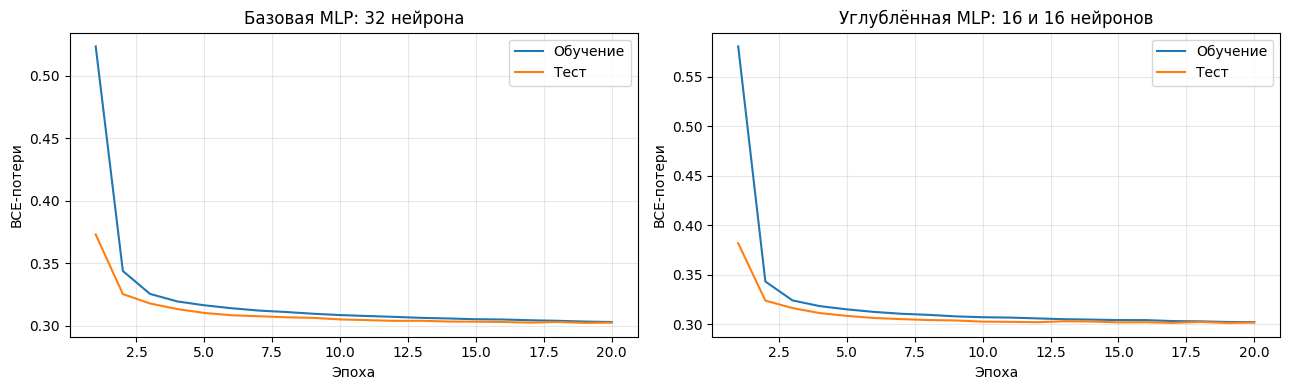

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, history, title in zip(
    axes,
    [history_basic, history_deep],
    ['Базовая MLP: 32 нейрона', 'Углублённая MLP: 16 и 16 нейронов']
):
    ax.plot(range(1, EPOCHS + 1), history['train_loss'], label='Обучение')
    ax.plot(range(1, EPOCHS + 1), history['test_loss'], label='Тест')
    ax.set(title=title, xlabel='Эпоха', ylabel='BCE-потери')
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Оценка качества классификации




In [7]:
def evaluate_model(model):
    model.eval()
    with torch.no_grad():
        logits = model(X_test_tensor.to(DEVICE))
        probabilities = torch.sigmoid(logits).cpu().numpy().ravel()
    predictions = (probabilities >= 0.5).astype(int)
    real = y_test.ravel().astype(int)
    metrics = {
        'Accuracy': accuracy_score(real, predictions),
        'Precision': precision_score(real, predictions, zero_division=0),
        'Recall': recall_score(real, predictions, zero_division=0),
        'F1-score': f1_score(real, predictions, zero_division=0)
    }
    return metrics, predictions

metrics_basic, pred_basic = evaluate_model(model_basic)
metrics_deep, pred_deep = evaluate_model(model_deep)

comparison = pd.DataFrame({
    'Базовая (32)': {**metrics_basic, 'Время обучения, с': time_basic},
    'Углублённая (16+16)': {**metrics_deep, 'Время обучения, с': time_deep}
})
print('Сравнение архитектур (метрики для класса >50K):')
display(comparison.round(4))

print('Базовая модель — отчёт о классификации:')
print(classification_report(y_test.ravel().astype(int), pred_basic,
                            target_names=['Доход ≤50K', 'Доход >50K'], zero_division=0))
print('Углублённая модель — отчёт о классификации:')
print(classification_report(y_test.ravel().astype(int), pred_deep,
                            target_names=['Доход ≤50K', 'Доход >50K'], zero_division=0))

Сравнение архитектур (метрики для класса >50K):


,Базовая (32),Углублённая (16+16)
Accuracy,0.8591,0.8617
Precision,0.7411,0.7465
Recall,0.6371,0.6441
F1-score,0.6852,0.6915
"Время обучения, с",8.3285,5.3977


Базовая модель — отчёт о классификации:
              precision    recall  f1-score   support

  Доход ≤50K       0.89      0.93      0.91      4945
  Доход >50K       0.74      0.64      0.69      1568

    accuracy                           0.86      6513
   macro avg       0.82      0.78      0.80      6513
weighted avg       0.85      0.86      0.86      6513

Углублённая модель — отчёт о классификации:
              precision    recall  f1-score   support

  Доход ≤50K       0.89      0.93      0.91      4945
  Доход >50K       0.75      0.64      0.69      1568

    accuracy                           0.86      6513
   macro avg       0.82      0.79      0.80      6513
weighted avg       0.86      0.86      0.86      6513



## 8. Матрицы ошибок

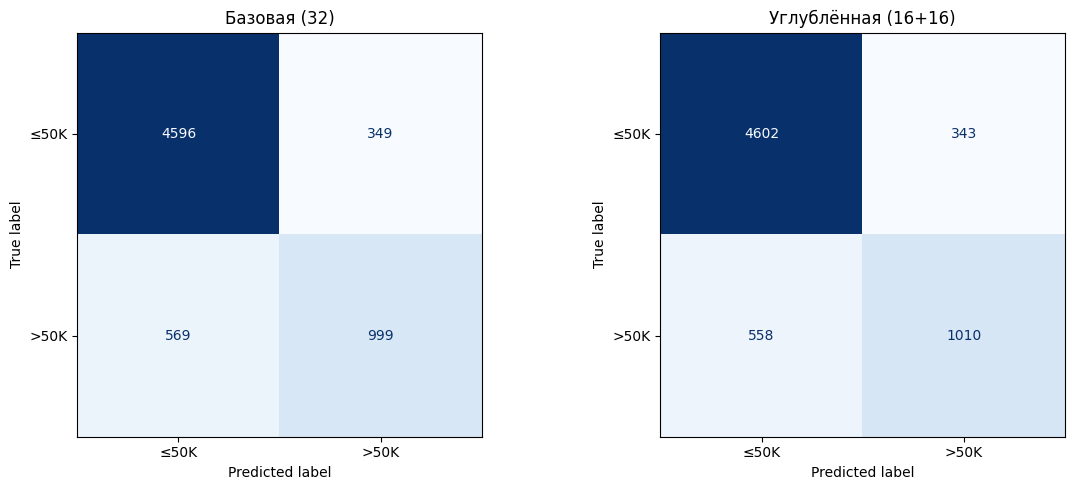

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
actual = y_test.ravel().astype(int)
for ax, prediction, title in zip(
    axes, [pred_basic, pred_deep], ['Базовая (32)', 'Углублённая (16+16)']
):
    ConfusionMatrixDisplay.from_predictions(
        actual, prediction, labels=[0, 1],
        display_labels=['≤50K', '>50K'],
        cmap='Blues', colorbar=False, ax=ax
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [9]:
best_accuracy = comparison.loc['Accuracy'].idxmax()
best_f1 = comparison.loc['F1-score'].idxmax()
print('РЕЗУЛЬТАТЫ ЭКСПЕРИМЕНТА')
print(f'Точность базовой сети: {metrics_basic["Accuracy"]:.4f}')
print(f'Точность углублённой сети: {metrics_deep["Accuracy"]:.4f}')
print(f'Изменение точности (углублённая − базовая): '
      f'{metrics_deep["Accuracy"] - metrics_basic["Accuracy"]:+.4f}')
print(f'F1-score базовой сети: {metrics_basic["F1-score"]:.4f}')
print(f'F1-score углублённой сети: {metrics_deep["F1-score"]:.4f}')
print(f'Изменение F1-score: '
      f'{metrics_deep["F1-score"] - metrics_basic["F1-score"]:+.4f}')
print(f'Более точная модель: {best_accuracy}')
print(f'Лучшая по F1-score: {best_f1}')
print('Вывод: увеличение глубины сети не гарантирует улучшения качества. '
      'Окончательный вывод следует делать по рассчитанным метрикам.')

РЕЗУЛЬТАТЫ ЭКСПЕРИМЕНТА
Точность базовой сети: 0.8591
Точность углублённой сети: 0.8617
Изменение точности (углублённая − базовая): +0.0026
F1-score базовой сети: 0.6852
F1-score углублённой сети: 0.6915
Изменение F1-score: +0.0064
Более точная модель: Углублённая (16+16)
Лучшая по F1-score: Углублённая (16+16)
Вывод: увеличение глубины сети не гарантирует улучшения качества. Окончательный вывод следует делать по рассчитанным метрикам.
